<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/01_house_rent_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

# House Rent Prediction with Linear and Ridge Regression

## Research question

How accurately can basic property and tenant-preference variables predict monthly house rent, and does Ridge regularization improve an ordinary least-squares (OLS) linear baseline?

**Purpose.** This is an educational regression study. The target is monthly `Rent`, modeled as `log1p(Rent)` during training to reduce the effect of very large rents. Final errors are converted back to the original rent units so that the results are easy to interpret.

> **Important interpretation note:** A score above 90% is not automatically overfitting. Overfitting is suspected when training performance is much better than cross-validation or untouched-test performance. This notebook therefore compares cross-validation, a holdout test set, and a simple baseline.

## 1. Basic definitions and formulas

### What type of problem is this?

This is **supervised learning** because the dataset contains examples with a known answer (`Rent`). It is a **regression** problem because the answer is a continuous number, not a class label.

| Term | Simple meaning |
| --- | --- |
| Regression | Predict a numerical value, such as monthly rent. |
| Classification | Predict a category, such as phishing/not phishing. |
| Feature (`X`) | An input used to make a prediction, such as `Size` or `City`. |
| Target (`y`) | The value the model tries to predict, here `Rent`. |
| Training data | Data used to learn model parameters. |
| Test data | Unseen data used once for a final performance estimate. |
| Linear regression | Finds a weighted straight-line relationship between features and a numerical target. |
| OLS | Ordinary Least Squares: chooses coefficients that make squared prediction errors as small as possible. |
| Ridge regression | Linear regression with a penalty that discourages very large coefficients. |
| KNN | Predicts from the closest observations; it is not used here because this notebook focuses on regression baselines. |
| Decision tree | Splits data into rule-based regions; it is not used here. |
| SVM | Finds a separating boundary or regression function with a maximum-margin idea; it is not used here. |

### Universal linear-regression formula

$$\hat{y} = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p$$

- $\hat{y}$ = predicted rent (or predicted log-rent while training)
- $\beta_0$ = intercept: prediction when all numeric inputs are zero
- $\beta_j$ = coefficient/weight for feature $j$
- $x_j$ = value of feature $j$
- $p$ = number of input features after encoding

OLS minimizes the **sum of squared errors**:

$$SSE = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

Ridge minimizes a similar objective with a coefficient penalty:

$$SSE + \alpha\sum_{j=1}^{p}\beta_j^2$$

Here, $\alpha$ controls the strength of regularization. A larger $\alpha$ usually shrinks coefficients more.

## 2. Dataset, source, and problem statement

**Source.** [House Rent Prediction Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/house-rent-prediction-dataset), published by `iamsouravbanerjee` on Kaggle. The original file is `House_Rent_Dataset.csv`. The repository intentionally does not redistribute the downloaded CSV; place it beside this notebook, in `data/`, or in `/content/` when running in Colab.

**Problem statement.** Given property characteristics and listing preferences, estimate a reasonable monthly rent. This can support an initial price estimate, while recognizing that a small public listing dataset is not a complete valuation system.

**Dataset details.** The expected columns include:

- `Rent`: monthly rent and the prediction target.
- `BHK`, `Size`, `Bathroom`: numerical property measurements.
- `Area Type`, `City`, `Furnishing Status`, `Tenant Preferred`, `Point of Contact`: categorical predictors.
- `Posted On`, `Area Locality`, and `Floor`: available context that is excluded from this compact baseline for date, high-cardinality, or parsing reasons.

**INSIGHT - 1:** The target is a continuous monetary amount, so regression metrics are appropriate. Confusion-matrix metrics such as accuracy, precision, recall, and specificity are not appropriate unless rent is first converted into an artificial class.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer, roc_auc_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import scipy.stats as stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

DATA_FILENAME = "House_Rent_Dataset.csv"
candidates = [Path(DATA_FILENAME), Path("data") / DATA_FILENAME, Path("/content") / DATA_FILENAME]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "Download House_Rent_Dataset.csv from the Kaggle source in the markdown above "
        "and place it beside this notebook, in data/, or in /content/."
    )

df_raw = pd.read_csv(dataset_path)
required = {
    "Rent", "BHK", "Size", "Area Type", "City", "Furnishing Status",
    "Tenant Preferred", "Bathroom", "Point of Contact",
}
missing = required - set(df_raw.columns)
if missing:
    raise KeyError(f"Missing required columns: {sorted(missing)}")

print(f"Loaded {dataset_path}: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())
display(df_raw.dtypes.rename("dtype").to_frame())
display(df_raw.isna().sum().rename("missing_values").to_frame())

Loaded data/House_Rent_Dataset.csv: 4,746 rows x 12 columns


,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


,dtype
Posted On,str
BHK,int64
Rent,int64
Size,int64
Floor,str
Area Type,str
Area Locality,str
City,str
Furnishing Status,str
Tenant Preferred,str


,missing_values
Posted On,0
BHK,0
Rent,0
Size,0
Floor,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0


## 3. Data cleaning and preprocessing

The cleaning steps are deliberately visible instead of silently hidden:

1. Copy the data and remove exact duplicate rows.
2. Convert numeric columns safely; invalid values become missing.
3. Remove rows without a valid positive target because a rent cannot be learned from an unknown or non-positive answer.
4. Report missing values and let the modeling pipeline impute them using training-fold information only.
5. Identify extreme numeric observations with the IQR rule. The cleaned analysis table removes rows that are extreme in rent, size, BHK, or bathrooms; this avoids letting a few unusual listings dominate this introductory baseline.
6. Standardize numeric features and one-hot encode categorical features inside a pipeline. `Size Band` is created only for an interpretable EDA chart, not used as a model feature, so discretization does not replace the original measurement.

**IQR rule:** an observation is flagged when it is below $Q1-1.5(IQR)$ or above $Q3+1.5(IQR)$, where $IQR=Q3-Q1$.

Exact duplicate rows removed: 0
Rows removed for invalid/missing rent: 0
Rows flagged as numeric outliers: 615
Clean analysis table: 4,131 rows x 13 columns


,missing_after_conversion
Posted On,0
BHK,0
Rent,0
Size,0
Floor,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Posted On,4131,80,2022-07-06,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BHK,4131.0,NaN,NaN,NaN,1.924958,0.701216,1.0,1.0,2.0,2.0,4.0
Rent,4131.0,NaN,NaN,NaN,18797.221738,13407.163099,1200.0,9500.0,15000.0,24000.0,67000.0
Size,4131.0,NaN,NaN,NaN,839.12152,426.903414,10.0,500.0,800.0,1100.0,2170.0
Floor,4131,332,1 out of 2,371,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area Type,4131,3,Super Area,2330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area Locality,4131,1972,Electronic City,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,4131,6,Bangalore,840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Furnishing Status,4131,3,Semi-Furnished,1931,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenant Preferred,4131,3,Bachelors/Family,3055,NaN,NaN,NaN,NaN,NaN,NaN,NaN


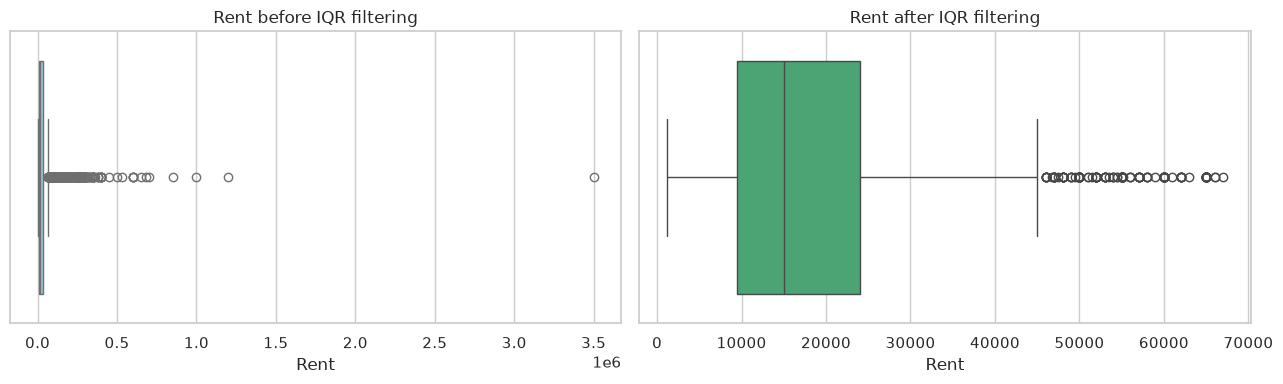

In [2]:
df = df_raw.copy()
before_rows = len(df)
df = df.drop_duplicates().copy()

numeric_columns = ["Rent", "BHK", "Size", "Bathroom"]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

invalid_target = df["Rent"].isna() | (df["Rent"] <= 0)
df = df.loc[~invalid_target].copy()

missing_after_conversion = df.isna().sum()
outlier_columns = ["Rent", "Size", "BHK", "Bathroom"]
outlier_flags = pd.DataFrame(index=df.index)
for column in outlier_columns:
    q1, q3 = df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_flags[column] = df[column].lt(lower) | df[column].gt(upper)

outlier_rows = outlier_flags.any(axis=1)
df_clean = df.loc[~outlier_rows].copy()
df_clean["Size Band"] = pd.cut(
    df_clean["Size"],
    bins=[-np.inf, 500, 1000, 2000, np.inf],
    labels=["Small (<=500)", "Medium (501-1000)", "Large (1001-2000)", "Very large (>2000)"],
)

print(f"Exact duplicate rows removed: {before_rows - len(df_raw.drop_duplicates()):,}")
print(f"Rows removed for invalid/missing rent: {invalid_target.sum():,}")
print(f"Rows flagged as numeric outliers: {outlier_rows.sum():,}")
print(f"Clean analysis table: {df_clean.shape[0]:,} rows x {df_clean.shape[1]:,} columns")
display(missing_after_conversion.rename("missing_after_conversion").to_frame())
display(df_clean.describe(include="all").T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="Rent", ax=axes[0], color="skyblue")
axes[0].set_title("Rent before IQR filtering")
sns.boxplot(data=df_clean, x="Rent", ax=axes[1], color="mediumseagreen")
axes[1].set_title("Rent after IQR filtering")
plt.tight_layout()
plt.show()

**INSIGHT - 2:** Duplicate and invalid-target checks protect the target from obvious data-quality errors. IQR filtering makes the introductory model less sensitive to extreme listings, but it also removes legitimate luxury or unusually small properties; this is a modeling choice, not a universal rule.

**INSIGHT - 3:** Missing values are not filled using the whole dataset. Median imputation for numeric variables and most-frequent imputation for categorical variables happen inside the training pipeline, which prevents test-set information from leaking into training.

**INSIGHT - 4:** `Size Band` is a discretized, human-readable view of `Size`. The original continuous `Size` remains in the model because replacing it with bins would discard useful information.

## 4. Exploratory data analysis

We inspect central tendency (mean and median), dispersion (standard deviation, range, and quartiles), distribution shape, normality, and correlations before fitting the model. The log transformation is used for modeling because rent is usually right-skewed; it does not claim that raw rent is normally distributed.

,mean,median,std,min,25%,50%,75%,max,iqr
Rent,18797.221738,15000.0,13407.163099,1200.0,9500.0,15000.0,24000.0,67000.0,14500.0
BHK,1.924958,2.0,0.701216,1.0,1.0,2.0,2.0,4.0,1.0
Size,839.121520,800.0,426.903414,10.0,500.0,800.0,1100.0,2170.0,600.0
Bathroom,1.765916,2.0,0.649202,1.0,1.0,2.0,2.0,3.0,1.0


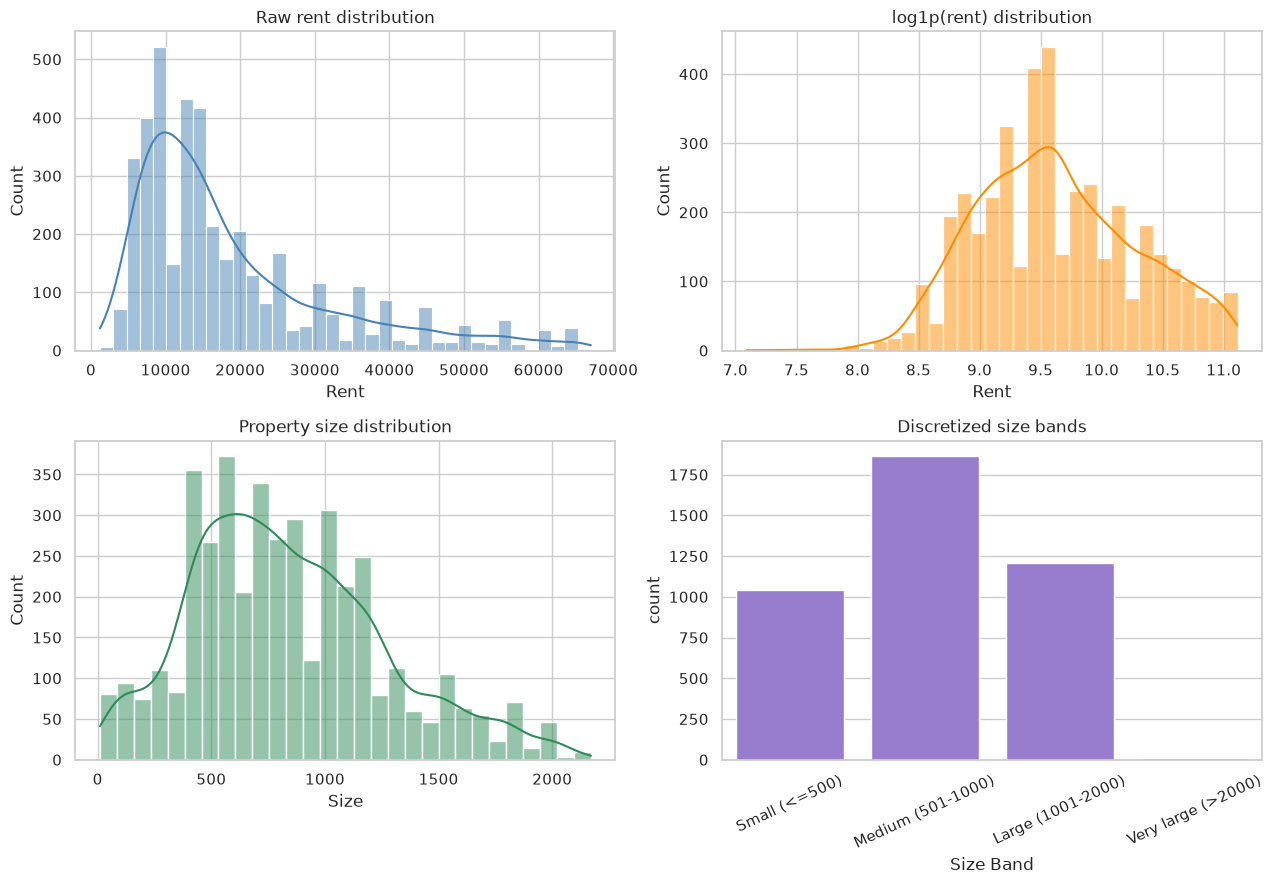

,variable,shapiro_statistic,p_value
0,Rent,0.837349,4.831036e-54
1,Size,0.973437,4.669270e-27
2,log_rent,0.986052,8.742836e-20


A small p-value rejects normality; with many observations, normality tests are sensitive, so the histograms are considered alongside the test.


,Rent,BHK,Size,Bathroom
Rent,1.000000,0.369056,0.337017,0.481981
BHK,0.369056,1.000000,0.683202,0.729978
Size,0.337017,0.683202,1.000000,0.656973
Bathroom,0.481981,0.729978,0.656973,1.000000


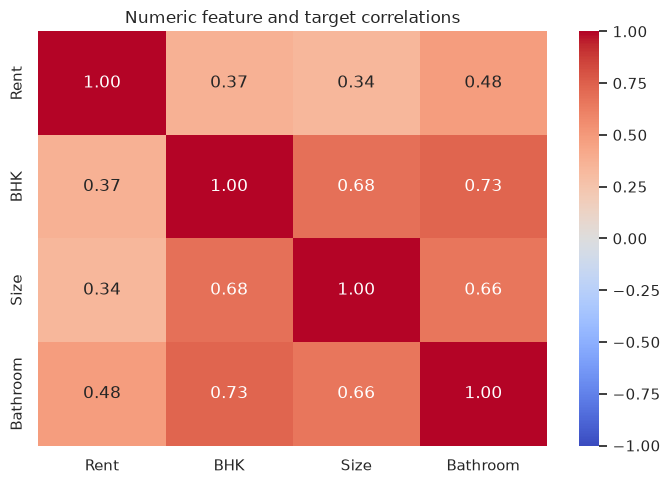

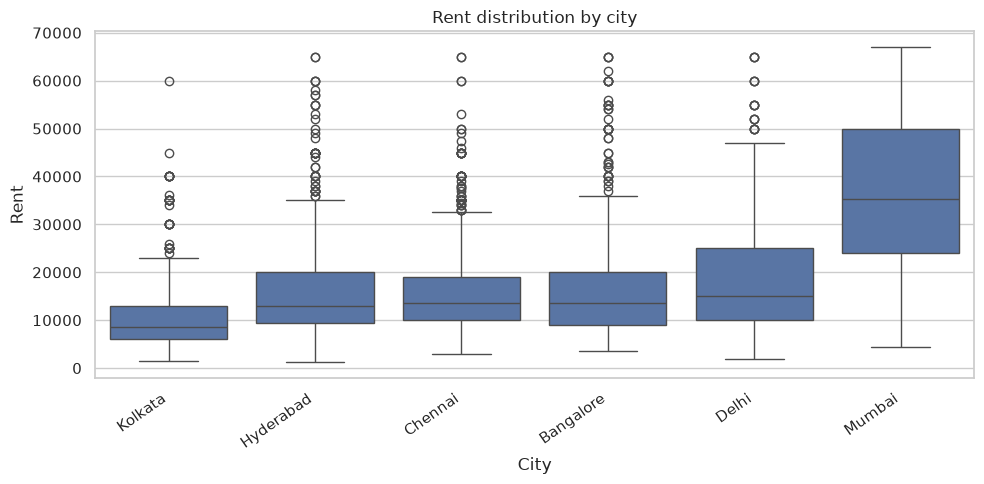

In [3]:
numeric_eda = ["Rent", "BHK", "Size", "Bathroom"]
summary = df_clean[numeric_eda].describe().T
summary["median"] = df_clean[numeric_eda].median()
summary["iqr"] = summary["75%"] - summary["25%"]
display(summary[["mean", "median", "std", "min", "25%", "50%", "75%", "max", "iqr"]])

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(df_clean["Rent"], kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Raw rent distribution")
sns.histplot(np.log1p(df_clean["Rent"]), kde=True, ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("log1p(rent) distribution")
sns.histplot(df_clean["Size"], kde=True, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Property size distribution")
sns.countplot(data=df_clean, x="Size Band", ax=axes[1, 1], color="mediumpurple")
axes[1, 1].tick_params(axis="x", rotation=25)
axes[1, 1].set_title("Discretized size bands")
plt.tight_layout()
plt.show()

normality_rows = []
for column in ["Rent", "Size", "log_rent"]:
    values = np.log1p(df_clean["Rent"]) if column == "log_rent" else df_clean[column]
    sample = values.dropna().sample(min(5000, len(values)), random_state=42)
    statistic, p_value = stats.shapiro(sample)
    normality_rows.append({"variable": column, "shapiro_statistic": statistic, "p_value": p_value})
normality = pd.DataFrame(normality_rows)
display(normality)
print("A small p-value rejects normality; with many observations, normality tests are sensitive, so the histograms are considered alongside the test.")

correlation = df_clean[["Rent", "BHK", "Size", "Bathroom"]].corr()
display(correlation)
plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Numeric feature and target correlations")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x="City", y="Rent", order=df_clean.groupby("City")["Rent"].median().sort_values().index)
plt.xticks(rotation=35, ha="right")
plt.title("Rent distribution by city")
plt.tight_layout()
plt.show()

**INSIGHT - 5:** The mean and median show whether rent is pulled upward by expensive listings; the standard deviation and IQR show how spread out typical rents are. A large mean-minus-median gap supports using `log1p(Rent)` for training.

**INSIGHT - 6:** The raw-rent histogram is expected to be right-skewed. If the log-rent histogram is more balanced, the transformation makes a linear baseline more reasonable, although the residual diagnostics still need to be checked.

**INSIGHT - 7:** Correlation measures linear association, not causation. A strong relationship between `Size` and `Rent` would support keeping `Size`, while a weak relationship would not by itself justify deleting a categorical variable such as `City`.

**INSIGHT - 8:** The Shapiro-Wilk result is a diagnostic rather than a pass/fail requirement for prediction. The model is evaluated on held-out data; normality of the target itself is not required for useful predictions.

## 5. Feature selection and processing

The compact feature set is:

`BHK`, `Size`, `Bathroom`, `Area Type`, `City`, `Furnishing Status`, `Tenant Preferred`, and `Point of Contact`.

These are retained because they describe property scale, location, furnishing, intended tenant, and listing contact. `Posted On` is excluded because it is a collection/listing date, `Area Locality` is high-cardinality and can create sparse, unstable categories, and raw `Floor` needs domain-specific parsing. These are baseline decisions, not proof that the excluded columns are irrelevant.

The split is **80% training and 20% testing** with `random_state=42`. The training portion learns preprocessing and coefficients; the untouched test portion estimates performance on unseen listings. Five-fold cross-validation inside the training workflow provides a more stable comparison than one split alone.

In [4]:
feature_cols = [
    "BHK", "Size", "Area Type", "City", "Furnishing Status",
    "Tenant Preferred", "Bathroom", "Point of Contact",
]
numeric_features = ["BHK", "Size", "Bathroom"]
categorical_features = [column for column in feature_cols if column not in numeric_features]

X = df_clean[feature_cols].copy()
y = np.log1p(df_clean["Rent"].astype(float))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

try:
    encoder = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", drop="first", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_features,
        ),
        (
            "categorical",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", encoder),
                ]
            ),
            categorical_features,
        ),
    ]
)

ols_model = Pipeline([("preprocess", preprocessor), ("regressor", LinearRegression())])
ridge_model = Pipeline([("preprocess", preprocessor), ("regressor", Ridge(alpha=1.0))])
baseline_model = Pipeline(
    [("preprocess", preprocessor), ("regressor", DummyRegressor(strategy="median"))]
)

print(f"Training rows: {len(X_train):,} ({len(X_train) / len(X):.0%})")
print(f"Testing rows: {len(X_test):,} ({len(X_test) / len(X):.0%})")
print(f"Numeric features: {numeric_features}")
print(f"Categorical features: {categorical_features}")

Training rows: 3,304 (80%)
Testing rows: 827 (20%)
Numeric features: ['BHK', 'Size', 'Bathroom']
Categorical features: ['Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']


**INSIGHT - 9:** One-hot encoding changes categories into 0/1 indicator columns so a linear model can use them. `handle_unknown="ignore"` keeps prediction possible when a test listing contains a category not seen during fitting.

**INSIGHT - 10:** Standardization gives numeric columns comparable scale: each transformed value is approximately $(x-\mu)/\sigma$. It is fitted only on training data. This is especially important for Ridge because its coefficient penalty depends on feature scale.

## 6. Model implementation and performance

The models are:

1. **Median baseline:** predicts the training median for every listing; it answers whether the learned models add value.
2. **OLS:** fits the ordinary linear-regression formula.
3. **Ridge:** fits the same encoded inputs while shrinking coefficients with $\alpha=1.0$.

Because this is regression, a confusion matrix and classification measures (accuracy, precision, recall/sensitivity, specificity, and ROC-AUC) are not calculated. They require discrete class labels and would be misleading for continuous rent. The relevant evaluation measures are SSE, MSE, RMSE, MAE, and $R^2$.

In [5]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


scoring = {
    "r2": "r2",
    "mae_log": "neg_mean_absolute_error",
    "rmse_log": make_scorer(rmse, greater_is_better=False),
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
model_candidates = [
    ("Median baseline", baseline_model),
    ("OLS", ols_model),
    ("Ridge", ridge_model),
]

cv_rows = []
for name, estimator in model_candidates:
    result = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append(
        {
            "model": name,
            "cv_r2_mean": result["test_r2"].mean(),
            "cv_r2_std": result["test_r2"].std(),
            "cv_mae_log": -result["test_mae_log"].mean(),
            "cv_rmse_log": -result["test_rmse_log"].mean(),
        }
    )
cv_results = pd.DataFrame(cv_rows).sort_values("cv_r2_mean", ascending=False)
display(cv_results)

ols_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)
baseline_model.fit(X_train, y_train)

y_pred_log = ols_model.predict(X_test)
y_pred_actual = np.maximum(0, np.expm1(y_pred_log))
y_test_actual = np.expm1(y_test)

def regression_metrics(y_true, y_pred):
    errors = y_true - y_pred
    sse = np.sum(errors ** 2)
    mse = mean_squared_error(y_true, y_pred)
    return {
        "SSE": sse,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

holdout_metrics = pd.DataFrame(
    {
        "OLS (original rent units)": regression_metrics(y_test_actual, y_pred_actual),
        "OLS (log-rent units)": regression_metrics(y_test, y_pred_log),
    }
)
display(holdout_metrics)
print(
    f"Mean absolute error means the typical prediction is off by about "
    f"{holdout_metrics.loc['MAE', 'OLS (original rent units)']:.2f} rent units "
    "on this holdout."
)

/tmp/mltech-venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/tmp/mltech-venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/tmp/mltech-venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/tmp/mltech-venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/tmp/mltech-venv/lib

/tmp/mltech-venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,model,cv_r2_mean,cv_r2_std,cv_mae_log,cv_rmse_log
2,Ridge,0.702873,0.034207,0.271377,0.355556
1,OLS,0.702851,0.034181,0.271335,0.355569
0,Median baseline,-0.006820,0.011601,0.528356,0.655680


,OLS (original rent units),OLS (log-rent units)
SSE,4.572054e+10,103.108543
MSE,5.528481e+07,0.124678
RMSE,7.435375e+03,0.353097
MAE,4.978037e+03,0.273151
R2,6.942154e-01,0.712117


Mean absolute error means the typical prediction is off by about 4978.04 rent units on this holdout.


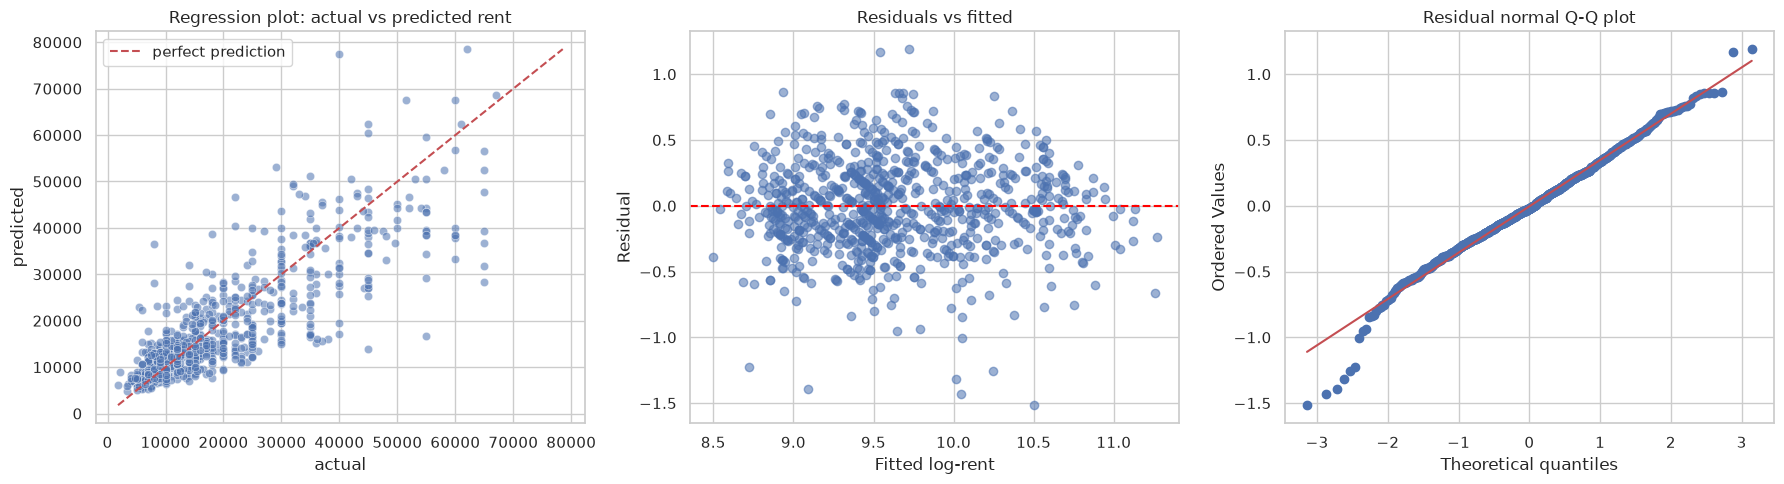

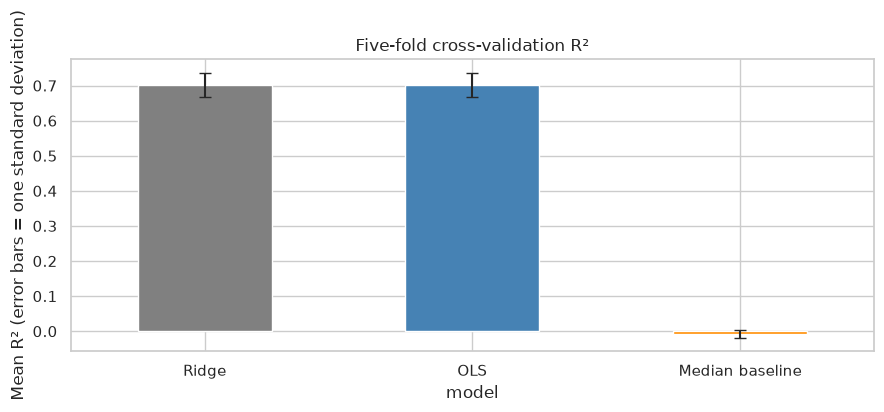


Supplemental classification threshold: 15000.00 rent units
This binary view is not a replacement for the continuous-rent regression evaluation.


Predicted,Low/predicted,High/predicted
Actual,,
Low/actual,55,47
High/actual,30,24


,value
Accuracy,0.506410
Precision,0.338028
Recall / Sensitivity,0.444444
Specificity,0.539216
F1 score,0.384000
ROC-AUC,0.901872


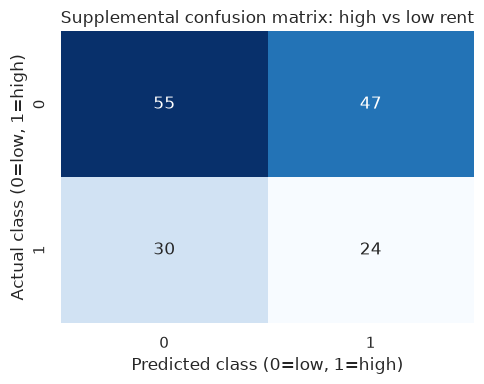

In [6]:
residuals = y_test - y_pred_log
comparison = pd.DataFrame({"actual": y_test_actual, "predicted": y_pred_actual})
comparison["absolute_error"] = (comparison["actual"] - comparison["predicted"]).abs()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=comparison, x="actual", y="predicted", alpha=0.55, ax=axes[0])
line_min = min(comparison["actual"].min(), comparison["predicted"].min())
line_max = max(comparison["actual"].max(), comparison["predicted"].max())
axes[0].plot([line_min, line_max], [line_min, line_max], "r--", label="perfect prediction")
axes[0].set_title("Regression plot: actual vs predicted rent")
axes[0].legend()

axes[1].scatter(y_pred_log, residuals, alpha=0.55)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Fitted log-rent", ylabel="Residual", title="Residuals vs fitted")

stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title("Residual normal Q-Q plot")
plt.tight_layout()
plt.show()

plot_results = cv_results.set_index("model")[["cv_r2_mean", "cv_r2_std"]]
plot_results["cv_r2_mean"].plot(
    kind="bar", yerr=plot_results["cv_r2_std"], capsize=4, color=["gray", "steelblue", "darkorange"],
    figsize=(9, 4), title="Five-fold cross-validation R²"
)
plt.ylabel("Mean R² (error bars = one standard deviation)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Confusion metrics are classification measures, so they are not primary
# regression metrics. For completeness, this supplemental view turns the
# continuous target into a transparent binary question: is rent above the
# training-set median? It must not be confused with the regression result.
classification_threshold = float(np.expm1(y_train.median()))
actual_high_rent = (y_test_actual >= classification_threshold).astype(int)
predicted_high_rent = (y_pred_actual >= classification_threshold).astype(int)
confusion = pd.crosstab(
    pd.Series(actual_high_rent, name="Actual"),
    pd.Series(predicted_high_rent, name="Predicted"),
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

tn, fp = confusion.loc[0, 0], confusion.loc[0, 1]
fn, tp = confusion.loc[1, 0], confusion.loc[1, 1]
classification_metrics = pd.DataFrame(
    {
        "value": [
            (tp + tn) / (tp + tn + fp + fn),
            tp / (tp + fp) if tp + fp else 0.0,
            tp / (tp + fn) if tp + fn else 0.0,
            tn / (tn + fp) if tn + fp else 0.0,
            (2 * tp) / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
            roc_auc_score(actual_high_rent, y_pred_actual),
        ]
    },
    index=["Accuracy", "Precision", "Recall / Sensitivity", "Specificity", "F1 score", "ROC-AUC"],
)

print(f"\nSupplemental classification threshold: {classification_threshold:.2f} rent units")
print("This binary view is not a replacement for the continuous-rent regression evaluation.")
display(confusion.rename(index={0: "Low/actual", 1: "High/actual"},
                          columns={0: "Low/predicted", 1: "High/predicted"}))
display(classification_metrics)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(
    title="Supplemental confusion matrix: high vs low rent",
    xlabel="Predicted class (0=low, 1=high)",
    ylabel="Actual class (0=low, 1=high)",
)
plt.tight_layout()
plt.show()


**INSIGHT - 11:** SSE is the total squared error, MSE is SSE divided by the number of observations, RMSE is MSE in the target's units, and MAE is the average absolute error. RMSE penalizes large mistakes more heavily than MAE.

**INSIGHT - 12:** $R^2$ compares the model with a mean-prediction reference: $R^2=1$ is perfect, $R^2=0$ is no better than that reference, and a negative value is worse. The baseline and model should be compared on the same split and metric.

**INSIGHT - 13:** The actual-vs-predicted plot should follow the diagonal. A curved pattern or a widening vertical spread suggests that a simple linear relationship misses structure or that error size changes with rent.

**INSIGHT - 14:** Residuals should be roughly centered around zero without a strong funnel or curve. The Q-Q plot is a descriptive check; it does not prove that the model is correct.

**INSIGHT - 15:** A solid model is not defined by one universal accuracy threshold. Here the decision is to prefer the model with better cross-validation and holdout error while keeping the train/test gap reasonable. A very high score would be investigated for leakage and overfitting, not rejected automatically.

## 7. Compare

**Model comparison.** Use the cross-validation table and untouched-test metrics to compare the median baseline, OLS, and Ridge. The preferred model is the one with lower validation error and a stronger or more stable $R^2$, not merely the one with the highest training score.

**Regression comparison.** The actual-vs-predicted regression plot, residual plot, Q-Q plot, and cross-validation bar chart show different aspects of performance. The regression metrics (SSE, MSE, RMSE, MAE, and $R^2$) are the primary measures because rent is continuous.

**Classification comparison.** The confusion matrix and accuracy, precision, recall/sensitivity, specificity, F1, and ROC-AUC are included only as a supplemental high-rent/low-rent interpretation using the training median threshold. They do not replace the regression metrics and should not be reported as the model's rent-prediction accuracy.

**INSIGHT - 16:** A model can have a useful regression RMSE while making some high/low threshold mistakes. The two evaluation views answer different questions.

## 8. Summarize

The notebook loads the documented Kaggle house-rent dataset, removes duplicates and invalid targets, reports missing values, filters extreme numeric listings using an IQR rule, and visualizes distributions, size bands, city differences, and correlations. Numeric features are imputed and standardized, categorical features are one-hot encoded, and all learned preprocessing is fitted through the training pipeline.

The workflow compares a median baseline with OLS and Ridge using five-fold cross-validation and an untouched 20% holdout. It reports original-rent and log-rent regression metrics, then provides a clearly labeled binary threshold view so the requested confusion metrics can also be inspected without pretending that rent is naturally a classification target.

**INSIGHT - 17:** The strongest conclusion is the one supported consistently by cross-validation, holdout metrics, and diagnostic plots. A single high score is not enough evidence of a reliable model.

## 9. Conclude

**Model choice.** Select OLS or Ridge according to the displayed validation and holdout results. Prefer Ridge only when its regularization improves or stabilizes unseen-data performance; otherwise OLS is the simpler explanation.

**Limitations.** The random split represents listings similar to this source sample, not future market conditions. Public listings may contain location and sampling bias. IQR filtering may remove legitimate unusual properties. `Area Locality`, `Floor`, and the date are excluded from this first baseline. Log-target back-transformation can introduce retransformation bias, and neither correlations nor coefficients prove causation.

**Conclusion.** This is an interpretable educational baseline for estimating monthly rent. Its regression results are the main answer; the classification metrics are an explicitly supplemental threshold analysis. Further work should compare parsed floor/locality features, tune Ridge, use repeated validation, and evaluate on a time-based split.
